# 02. Baseline model comparison (report 3.2.1 baseline / 3.2.2 overfitting check)
- 데이터: `데이터_csv/영통구_행정동별_월별_학습데이터셋.csv` (01번 코드로 생성)
- 시간순 분할: 학습 2024.03~2025.09 / 테스트 2025.10~2026.09 (최근 12개월)
- 단순 기준모델 2개 + Logistic Regression / Random Forest / XGBoost
- 구성은 수업 노트북(ml2_EX "파이프라인 예시", "직원 퇴사예측")의 흐름을 따름:
  ColumnTransformer(StandardScaler + OneHotEncoder) → Pipeline → classification_report → 혼동행렬 히트맵 → ROC 커브
- 비교 실험을 하려면 아래 [CONFIG] 셀의 FEATURES, MODELS만 고치면 됨

VSCode에서 `# %%` 셀 단위로 실행(Run Cell)하거나 파일 전체를 실행하면 됨.
사전설치 : pip install pandas scikit-learn xgboost matplotlib seaborn

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, auc, classification_report, confusion_matrix, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

# 노트북에는 __file__이 없으므로 실행 위치(code 폴더 또는 ML 폴더)로 기준 폴더를 정함
DATA_DIR = (Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()) / "데이터_csv"
RESULT_PATH = DATA_DIR / "results_baseline_models.csv"

In [2]:
# [CONFIG] features, split, models — 비교 실험은 여기만 바꾸면 됨
TARGET = "outflow"
CAT_FEATURES = ["dong", "month"]
NUM_FEATURES = [
    "price_m2",
    "price_chg_1m", "price_chg_3m",           # "price_chg_12m"은 기본 모델에서 제외 (넣으면 학습 기간이 줄어듦)
    "price_chg_1m_lag2", "price_chg_1m_lag3",
    "trade_cnt", "trade_cnt_3m",
    "new_ratio", "build_year_avg",
    "pop_chg_rate_lag1", "population_lag1", "hh_size_lag1",
]
TRAIN_END = "2025-09"      # 이 월까지 학습, 다음 월부터 테스트
THRESHOLD = 0.5            # 유출 확률이 이 값 이상이면 유출(1)로 판정
RANDOM_STATE = 42

MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    # 노트북 "파이프라인 예시"의 XGBClassifier 설정과 동일
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE),
}

In [3]:
# Load data and split by time
df = pd.read_csv(DATA_DIR / "영통구_행정동별_월별_학습데이터셋.csv")
df = df.dropna(subset=CAT_FEATURES + NUM_FEATURES).reset_index(drop=True)   # 시작 구간의 구조적 결측 행 제외

# train_test_split(무작위 분할) 대신 시간 순서로 분할:
# 무작위로 섞으면 미래 월이 학습에 들어가 "과거로 미래를 예측"하는 상황이 깨지기 때문
train = df[df["ym"] <= TRAIN_END]
test = df[df["ym"] > TRAIN_END]
X_train, y_train = train[CAT_FEATURES + NUM_FEATURES], train[TARGET]
X_test, y_test = test[CAT_FEATURES + NUM_FEATURES], test[TARGET]

print(f"All   : {len(df)} rows ({df['ym'].min()} ~ {df['ym'].max()})")
print(f"Train : {len(train)} rows ({train['ym'].min()} ~ {train['ym'].max()}), outflow ratio {y_train.mean():.3f}")
print(f"Test  : {len(test)} rows ({test['ym'].min()} ~ {test['ym'].max()}), outflow ratio {y_test.mean():.3f}")

All   : 372 rows (2024-03 ~ 2026-09)
Train : 228 rows (2024-03 ~ 2025-09), outflow ratio 0.588
Test  : 144 rows (2025-10 ~ 2026-09), outflow ratio 0.569


In [4]:
# Evaluation helper
def evaluate(y_true, y_pred, y_prob=None):
    # 유출(1)을 양성 클래스로 보고 지표 계산
    # Precision/Recall/F1은 classification_report에서, ROC-AUC는 roc_curve + auc로 계산 (노트북 방식)
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    if y_prob is not None:
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)
    else:
        roc_auc = np.nan          # 확률이 없는 기준모델은 ROC-AUC 계산 불가
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": report["1"]["precision"],
        "Recall": report["1"]["recall"],
        "F1": report["1"]["f1-score"],
        "ROC-AUC": roc_auc,
    }


results = []

In [5]:
# Naive baselines (rule-based, no training)
# ① 전월 방향 유지: 지난달 인구가 줄었으면 이번 달도 유출로 예측
pred_last_month = (test["pop_chg_rate_lag1"] < 0).astype(int)
results.append({"model": "Baseline: last month", "split": "Test", **evaluate(y_test, pred_last_month)})

# ② 작년 같은 달 방향: 12개월 전 같은 행정동의 인구 증감 부호를 그대로 사용
#    학습 데이터셋보다 앞선 월(2024.10 이전)도 필요해서 인구현황 원본을 직접 읽음
pop = pd.read_csv(DATA_DIR / "영통구_행정동별_월별_인구현황.csv")
pop = pop[pop["구분"] == "행정동"]
last_year = pd.DataFrame({
    "ym": (pd.to_datetime(pop["기준년월"].astype(str), format="%Y%m") + pd.DateOffset(months=12)).dt.strftime("%Y-%m"),
    "dong": pop["행정동"].values,
    "pop_chg_last_year": pop["인구증감_전월대비"].values,
})
ly = test.merge(last_year, on=["ym", "dong"], how="left")
pred_last_year = (ly["pop_chg_last_year"] < 0).astype(int)
results.append({"model": "Baseline: same month last year", "split": "Test",
                **evaluate(ly[TARGET], pred_last_year)})

In [6]:
# ML models: preprocessing (scaling + one-hot) + classifier in one Pipeline
# 전처리를 Pipeline 안에 넣어 학습 데이터 기준으로만 스케일링되도록 함 (데이터 누수 방지)
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
])

pipelines = {}
for name, model in MODELS.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline
    for split, X, y in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        y_prob = pipeline.predict_proba(X)[:, 1]          # 두 번째 열 = 유출(1)일 확률
        results.append({"model": name, "split": split,
                        **evaluate(y, (y_prob >= THRESHOLD).astype(int), y_prob)})

res = pd.DataFrame(results).round(4)

In [7]:
# Result 1: test performance (report 3.2.1)
print(res[res["split"] == "Test"].drop(columns="split").to_string(index=False))

                         model  Accuracy  Precision  Recall     F1  ROC-AUC
          Baseline: last month    0.5972     0.6500  0.6341 0.6420      NaN
Baseline: same month last year    0.5764     0.6154  0.6829 0.6474      NaN
           Logistic Regression    0.5972     0.6176  0.7683 0.6848   0.6107
                 Random Forest    0.6389     0.6705  0.7195 0.6941   0.6356
                       XGBoost    0.6597     0.6701  0.7927 0.7263   0.6253


In [8]:
# Result 2: overfitting check — train vs test (report 3.2.2)
# 학습 성능과 테스트 성능의 차이(gap)가 클수록 과적합이 심함
ml = res[res["model"].isin(MODELS)]
gap = ml.pivot(index="model", columns="split", values=["Accuracy", "ROC-AUC"])
for m in ["Accuracy", "ROC-AUC"]:
    gap[(m, "Gap")] = gap[(m, "Train")] - gap[(m, "Test")]
print(gap.round(4))

                    Accuracy         ROC-AUC         Accuracy ROC-AUC
split                   Test   Train    Test   Train      Gap     Gap
model                                                                
Logistic Regression   0.5972  0.8026  0.6107  0.8845   0.2054  0.2738
Random Forest         0.6389  1.0000  0.6356  1.0000   0.3611  0.3644
XGBoost               0.6597  1.0000  0.6253  1.0000   0.3403  0.3747


In [9]:
# Save results
res.to_csv(RESULT_PATH, index=False, encoding="utf-8-sig")
print("Saved:", RESULT_PATH)

Saved: C:\Users\human-13\Desktop\ML\데이터_csv\results_baseline_models.csv


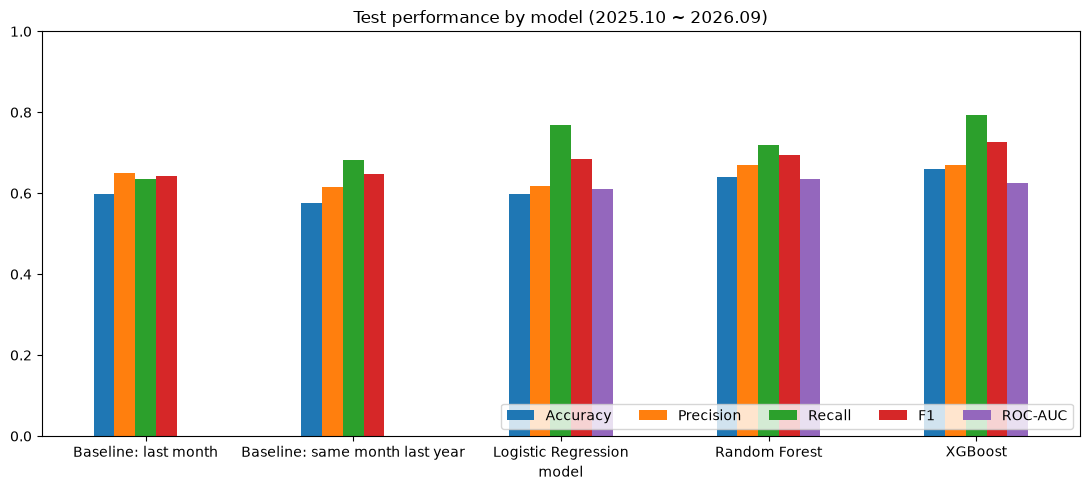

In [10]:
# Plot: test metrics by model
test_res = res[res["split"] == "Test"].set_index("model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
ax = test_res.plot(kind="bar", figsize=(11, 5), rot=0)
ax.set_title("Test performance by model (2025.10 ~ 2026.09)")
ax.set_ylim(0, 1)
ax.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.show()


[Random Forest] Classification Report
                 precision    recall  f1-score   support

Stay/Inflow (0)       0.59      0.53      0.56        62
    Outflow (1)       0.67      0.72      0.69        82

       accuracy                           0.64       144
      macro avg       0.63      0.63      0.63       144
   weighted avg       0.64      0.64      0.64       144



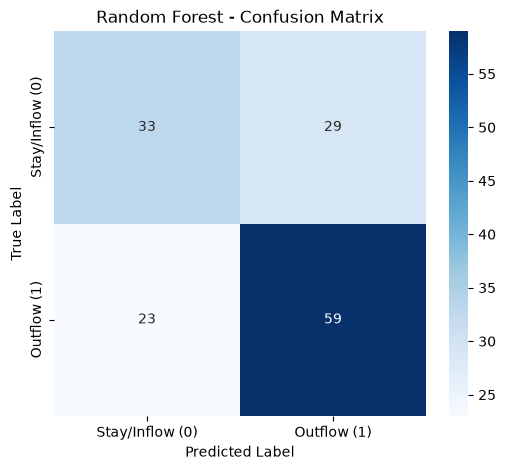

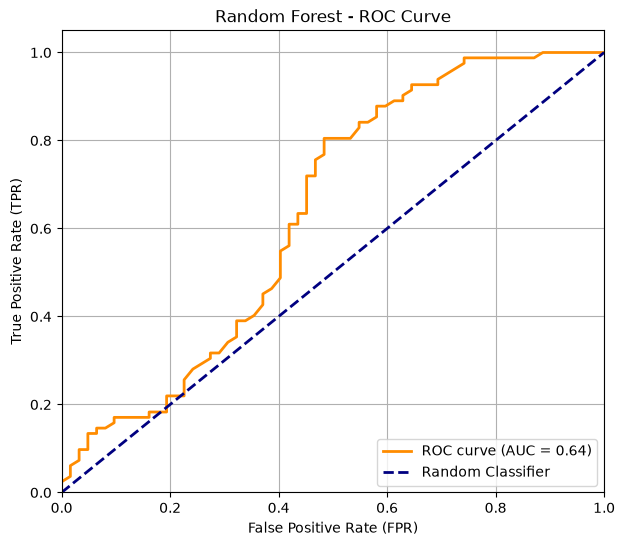

In [11]:
# Classification report, confusion matrix, ROC curve of one model
# 그래프를 볼 모델 이름만 바꾸면 됨 (MODELS의 키 중 하나)
MODEL_TO_PLOT = "Random Forest"
y_prob = pipelines[MODEL_TO_PLOT].predict_proba(X_test)[:, 1]
y_pred = (y_prob >= THRESHOLD).astype(int)
labels = ["Stay/Inflow (0)", "Outflow (1)"]

print(f"\n[{MODEL_TO_PLOT}] Classification Report")
print(classification_report(y_test, y_pred, target_names=labels))

# 혼동 행렬 히트맵 (annot=True: 셀 안에 숫자 표시, fmt="d": 정수로 표시)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title(f"{MODEL_TO_PLOT} - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# ROC 커브 (fpr: 거짓 양성률, tpr: 참 양성률), AUC가 1에 가까울수록 좋음
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Random Classifier")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title(f"{MODEL_TO_PLOT} - ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()